# GGA exchange-correlation potentials in real space 

**Author:** Egor Trushin  
**Date created:** 25/04/2025  
**Last modified:** 07/08/2025

## Introduction

The aim of this notebook is to introduce a codebase that allows the exchange-correlation (XC) potential of the generalized gradient approximation (GGA) density functional theory (DFT) method to be evaluated in real space using PySCF. Solving the self-consistent Kohn-Sham (KS) equation in Gaussian basis set codes does not require the construction of the XC potential in real space, $v_{xc}(\mathbf{r})$. During the self-consistent solution of the KS equations, $v_{xc}$ is constructed in the atomic orbital (AO) basis set representation. The construction of $v_{xc}^{GGA}$ in AO basis set representation is done avoiding second order derivatives of density, whereas these derivatives are required if we want to construct $v_{xc}^{GGA}$ in real space. Therefore, we need a bit of coding to obtain real-space GGA XC potential.

Discussion of this topic can be found in PySCF issues:
> https://github.com/pyscf/pyscf/issues/650

The Jupyter notebook with construction of PBE XC pontetial (in Chinese) can be found at:
> https://ajz34.readthedocs.io/zh-cn/latest/QC_Notes/XC_Potential_Series/PBE_xc_potential.html

In [1]:
import pyscf
print("PySCF version:", pyscf.__version__)

import numpy as np
import pandas as pd
from pyscf import gto, dft, lib

import matplotlib.pyplot as plt

import matplotlib
matplotlib.rcParams['text.usetex'] = True

PySCF version: 2.10.0


## Utility function

In [2]:
def gen_coords_1d(z_min, z_max, n_points):
    """Generate grid with linear distributed points along z-axis.

    Args:
      zmin: minumal z-value
      zmax: maximal z-value
      n_points: number of points

    Returns:
      coords: grid with points
    """
    z = np.linspace(z_min, z_max, n_points)
    coords = np.zeros([z.shape[0], 3])
    coords[:, 2] = z
    return coords

## Functions for evaluation of LDA and GGA potentials

In [3]:
def lda_vxc(mol, coords, dm, xc):
    """Evaluate the LDA exchange-correlation potential on a given real-space grid.

    Args:
      mol: PySCF molecule object
      coords: coordinates of grid on which the potential will be calculated
      dm: density matrix
      xc: xc string, i.e. xc='lda'

    Returns:
      vxc: exchange-correlation potential on grid
    """
    ao_value = dft.numint.eval_ao(mol, coords, deriv=0)
    rho = dft.numint.eval_rho(mol, ao_value, dm, xctype="LDA")
    _, vxc = dft.libxc.eval_xc(xc, rho)[:2]
    return vxc[0]

In [4]:
def gga_vxc(mol, coords, dm, xc):
    """Evaluate the GGA exchange-correlation potential on a given real-space grid.

    Args:
      mol: PySCF molecule object
      coords: coordinates of grid on which the potential will be calculated
      dm: density matrix
      xc: xc string, i.e. xc='pbe'

    Returns:
      vxc: exchange-correlation potential on grid
    """
    ao = dft.numint.eval_ao(mol, coords, deriv=2)
    ao_0, ao_1 = ao[0], ao[1:4]
    ao_2 = np.array(
        [
            [ao[4], ao[5], ao[6]],
            [ao[5], ao[7], ao[8]],
            [ao[6], ao[8], ao[9]],
        ]
    )

    rho_0 = np.einsum("gu, gv, uv -> g", ao_0, ao_0, dm)
    rho_1 = 2 * np.einsum("rgu, gv, uv -> rg", ao_1, ao_0, dm)
    rho_2 = +2 * np.einsum("rwgu, gv, uv -> rwg", ao_2, ao_0, dm) + 2 * np.einsum("rgu, wgv, uv -> rwg", ao_1, ao_1, dm)

    gamma_0 = np.einsum("rg, rg -> g", rho_1, rho_1)
    gamma_1 = 2 * np.einsum("rwg, wg -> rg", rho_2, rho_1)

    _, vxc, fxc, _ = dft.libxc.eval_xc(xc, np.concatenate([rho_0[None, :], rho_1]), deriv=2)
    fr, fg = vxc[:2]
    frr, frg, fgg = fxc[:3]

    vxc = (
        +fr
        - 2 * np.einsum("g, rg, rg -> g", frg, rho_1, rho_1)
        - 2 * np.einsum("g, rg, rg -> g", fgg, gamma_1, rho_1)
        - 2 * np.einsum("g, gr -> g", fg, rho_2.diagonal())
    )
    return vxc

Alternative implementation which is not used in this notebook:

In [5]:
def gga_vxc_v2(mol, coords, dm, xc):
    """Evaluate the GGA exchange-correlation potential on a given real-space grid.

    Args:
      mol: PySCF molecule object
      coords: coordinates of grid on which the potential will be calculated
      dm: density matrix
      xc: xc string, i.e. xc='pbe'

    Returns:
      vxc: exchange-correlation potential on grid
    """
    ao = dft.numint.eval_ao(mol, coords, deriv=2)
    ao_0 = ao[0]
    ao_1 = ao[1:4]
    ao_x, ao_y, ao_z = ao[1:4]
    ao_xx, ao_xy, ao_xz, ao_yy, ao_yz, ao_zz = ao[4:10]

    ao_2 = np.array([[ao_xx, ao_xy, ao_xz], [ao_xy, ao_yy, ao_yz], [ao_xz, ao_yz, ao_zz]])

    if dm.ndim == 2:
        rho = dft.numint.eval_rho(mol, ao, dm, xctype="MGGA")
        rho_0 = rho[0]
        rho_x = rho[1]
        rho_y = rho[2]
        rho_z = rho[3]
        rho_del = np.array([rho_x, rho_y, rho_z])
        rho_lapl = rho[4]
        rho_tau = rho[5]

        rho_2 = 2 * lib.einsum("rwiu, iv, uv -> rwi", ao_2, ao_0, dm) + 2 * lib.einsum(
            "riu, wiv, uv -> rwi", ao_1, ao_1, dm
        )

        gamma = rho_x**2 + rho_y**2 + rho_z**2

        del_gamma = 2 * lib.einsum("rwi, wi -> ri", rho_2, rho_del)

        vxc, fxc = dft.libxc.eval_xc(xc, rho[:4], deriv=2)[1:3]

        vrho, vsigma = vxc[:2]
        vrho2, vrhosigma, vsigma2 = fxc[:3]

        vxc = (
            vrho
            - 2 * lib.einsum("i,i->i", vrhosigma, gamma)
            - 2 * lib.einsum("i,ri,ri->i", vsigma2, del_gamma, rho_del)
            - 2 * lib.einsum("i,i->i", vsigma, rho_lapl)
        )
        return vxc

## Calculations

### N$_2$
We are going to reproduce Figure 1 from
> M. Grüning, O.V. Gritsenko, S.J.A. van Gisbergen, E.J. Baerends J. Chem. Phys. 116, 9591–9601 (2002). https://doi.org/10.1063/1.1476007

I assume that GGA in this paper is `GGA_X_B86+GGA_C_PW91`, but I do not know this exactly.

In [6]:
coords = gen_coords_1d(0, 10, 10000)

mol = gto.M(atom=f"N 0. 0. -0.55015; N 0. 0. 0.55015", basis="aug-cc-pV5Z", symmetry=False)
mol.verbose = 0

# LDA
mf = dft.RKS(mol, xc="LDA_X, LDA_C_VWN_RPA").density_fit().run()
dm = mf.make_rdm1()
vxc_lda = lda_vxc(mol, coords, dm, "LDA_X, LDA_C_VWN_RPA")

# GGA
mf = dft.RKS(mol, xc="GGA_X_B86, GGA_C_PW91").density_fit().run()
dm = mf.make_rdm1()
vxc_pbe = gga_vxc(mol, coords, dm, "GGA_X_B86, GGA_C_PW91")

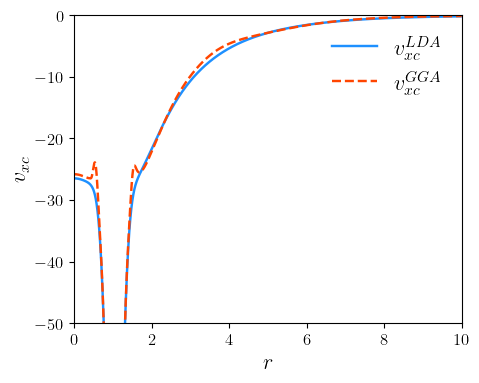

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(coords[:, 2], vxc_lda * 27.2114, color="dodgerblue", label="$v_{xc}^{LDA}$")
ax.plot(coords[:, 2], vxc_pbe * 27.2114, "--", color="orangered", label="$v_{xc}^{GGA}$")
ax.legend(frameon=False, fontsize=16)
ax.set_xlim(0, 10)
ax.set_ylim(-50, 0)
ax.set_xlabel("$r$", fontsize=16)
ax.set_ylabel("$v_{xc}$", fontsize=16)

plt.show()

### He$_2$

We are going to reproduce left upper panel of Figures 1 and 3 from
> A. Buksztel, S. Śmiga, I. Grabowski Advances in Quantum Chemistry. 73, 263-283 (2016). https://doi.org/10.1016/bs.aiq.2015.07.002

In [8]:
coords = gen_coords_1d(-20, 20, 10000)

mol = gto.M(atom=f"He 0. 0. -1.4817; He 0. 0. 1.4817", basis="aug-cc-pV5Z", symmetry=False)
mol.verbose = 0

# LDA
mf = dft.RKS(mol, xc="LDA_X, LDA_C_VWN_RPA").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_svwn = lda_vxc(mol, coords, dm, "LDA_X, LDA_C_VWN_RPA")
vc_svwn = lda_vxc(mol, coords, dm, "LDA_C_VWN_RPA")

# GGA

mf = dft.RKS(mol, xc="GGA_X_B86, GGA_C_LYP").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_blyp = gga_vxc(mol, coords, dm, "GGA_X_B86, GGA_C_LYP")
vc_blyp = gga_vxc(mol, coords, dm, "GGA_C_LYP")

mf = dft.RKS(mol, xc="GGA_X_PBE, GGA_C_PBE").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_pbe = gga_vxc(mol, coords, dm, "GGA_X_PBE, GGA_C_PBE")
vc_pbe = gga_vxc(mol, coords, dm, "GGA_C_PBE")

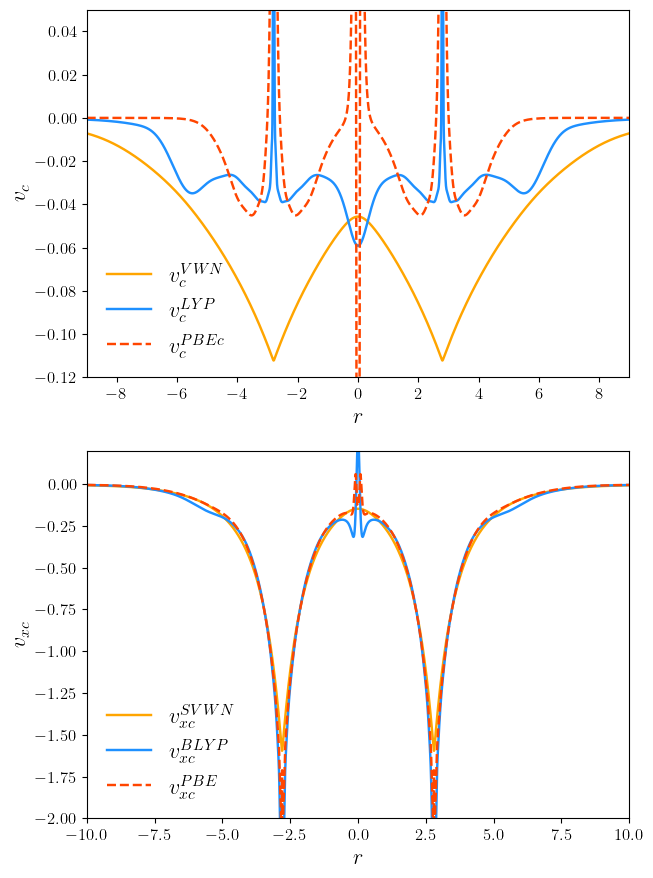

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(7, 10.5))

axs[0].plot(coords[:, 2], vc_svwn, color="orange", label="$v_c^{VWN}$")
axs[0].plot(coords[:, 2], vc_blyp, color="dodgerblue", label="$v_c^{LYP}$")
axs[0].plot(coords[:, 2], vc_pbe, "--", color="orangered", label="$v_c^{PBEc}$")
axs[0].legend(frameon=False, fontsize=16)
axs[0].set_ylim(-0.12, 0.05)
axs[0].set_xlim(-9, 9)
axs[0].set_xlabel("$r$", fontsize=16)
axs[0].set_ylabel("$v_c$", fontsize=16)

axs[1].plot(coords[:, 2], vxc_svwn, color="orange", label="$v_{xc}^{SVWN}$")
axs[1].plot(coords[:, 2], vxc_blyp, color="dodgerblue", label="$v_{xc}^{BLYP}$")
axs[1].plot(coords[:, 2], vxc_pbe, "--", color="orangered", label="$v_{xc}^{PBE}$")
axs[1].legend(frameon=False, fontsize=16)
axs[1].set_ylim(-2.0, 0.2)
axs[1].set_xlim(-10, 10)
axs[1].set_xlabel("$r$", fontsize=16)
axs[1].set_ylabel("$v_{xc}$", fontsize=16)

plt.show()

### ArNe
We are going to reproduce left upper panel of Figures 2 and 4 from
> A. Buksztel, S. Śmiga, I. Grabowski Advances in Quantum Chemistry. 73, 263-283 (2016). https://doi.org/10.1016/bs.aiq.2015.07.002

In [10]:
mol = gto.M(atom=f"Ne 0. 0. -1.7445; Ar 0. 0. 1.7445", basis="aug-cc-pV5Z", symmetry=False)
mol.verbose = 0

# LDA
mf = dft.RKS(mol, xc="LDA_X, LDA_C_VWN_RPA").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_svwn = lda_vxc(mol, coords, dm, "LDA_X, LDA_C_VWN_RPA")
vc_svwn = lda_vxc(mol, coords, dm, "LDA_C_VWN_RPA")

# GGA

mf = dft.RKS(mol, xc="GGA_X_B86, GGA_C_LYP").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_blyp = gga_vxc(mol, coords, dm, "GGA_X_B86, GGA_C_LYP")
vc_blyp = gga_vxc(mol, coords, dm, "GGA_C_LYP")

mf = dft.RKS(mol, xc="GGA_X_PBE, GGA_C_PBE").density_fit(auxbasis="aug-cc-pV5Z-RI").run()
dm = mf.make_rdm1()
vxc_pbe = gga_vxc(mol, coords, dm, "GGA_X_PBE, GGA_C_PBE")
vc_pbe = gga_vxc(mol, coords, dm, "GGA_C_PBE")

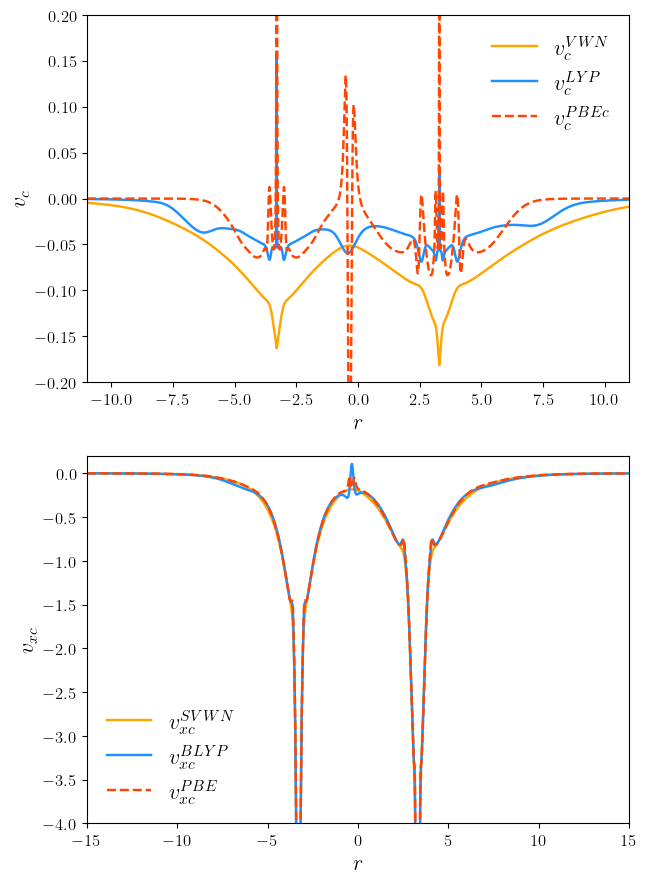

In [11]:
fig, axs = plt.subplots(2, 1, figsize=(7, 10.5))

axs[0].plot(coords[:, 2], vc_svwn, color="orange", label="$v_c^{VWN}$")
axs[0].plot(coords[:, 2], vc_blyp, color="dodgerblue", label="$v_c^{LYP}$")
axs[0].plot(coords[:, 2], vc_pbe, "--", color="orangered", label="$v_c^{PBEc}$")
axs[0].legend(frameon=False, fontsize=16)
axs[0].set_ylim(-0.2, 0.2)
axs[0].set_xlim(-11, 11)
axs[0].set_xlabel("$r$", fontsize=16)
axs[0].set_ylabel("$v_c$", fontsize=16)

axs[1].plot(coords[:, 2], vxc_svwn, color="orange", label="$v_{xc}^{SVWN}$")
axs[1].plot(coords[:, 2], vxc_blyp, color="dodgerblue", label="$v_{xc}^{BLYP}$")
axs[1].plot(coords[:, 2], vxc_pbe, "--", color="orangered", label="$v_{xc}^{PBE}$")
axs[1].legend(frameon=False, fontsize=16)
axs[1].set_ylim(-4.0, 0.2)
axs[1].set_xlim(-15, 15)
axs[1].set_xlabel("$r$", fontsize=16)
axs[1].set_ylabel("$v_{xc}$", fontsize=16)

plt.show()

### CO

In [12]:
coords = gen_coords_1d(-10., 10., 10000)

mol = gto.M(atom=f"C 0. 0. -0.646514; O 0. 0. 0.484886", basis="aug-cc-pVQZ", symmetry=False)
mol.verbose = 0

# LDA
mf = dft.RKS(mol, xc="LDA_X, LDA_C_VWN_RPA").density_fit().run()
dm = mf.make_rdm1()
vxc_lda = lda_vxc(mol, coords, dm, "LDA_X, LDA_C_VWN_RPA")
vx_lda = lda_vxc(mol, coords, dm, "LDA_X")
vc_lda = lda_vxc(mol, coords, dm, "LDA_C_VWN_RPA")

# GGA
mf = dft.RKS(mol, xc="GGA_X_PBE, GGA_C_PBE").density_fit().run()
dm = mf.make_rdm1()
vxc_pbe = gga_vxc(mol, coords, dm, "GGA_X_PBE, GGA_C_PBE")
vx_pbe = gga_vxc(mol, coords, dm, "GGA_X_PBE")
vc_pbe = gga_vxc(mol, coords, dm, "GGA_C_PBE")

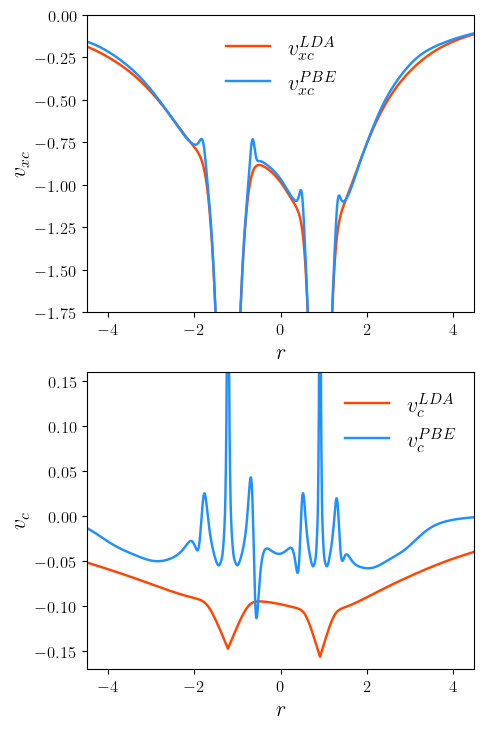

In [13]:
fig, axs = plt.subplots(2, 1, figsize=(5, 8.5))

axs[0].plot(coords[:, 2], vxc_lda, color="orangered", label="$v_{xc}^{LDA}$")
axs[0].plot(coords[:, 2], vxc_pbe, color="dodgerblue", label="$v_{xc}^{PBE}$")
axs[0].legend(frameon=False, fontsize=16)
axs[0].set_xlim(-4.5, 4.5)
axs[0].set_ylim(-1.75, 0)
axs[0].set_xlabel("$r$", fontsize=16)
axs[0].set_ylabel("$v_{xc}$", fontsize=16)

axs[1].plot(coords[:, 2], vc_lda, color="orangered", label="$v_c^{LDA}$")
axs[1].plot(coords[:, 2], vc_pbe, color="dodgerblue", label="$v_c^{PBE}$")
axs[1].legend(frameon=False, fontsize=16)
axs[1].set_xlim(-4.5, 4.5)
axs[1].set_ylim(-0.17, 0.16)
axs[1].set_xlabel("$r$", fontsize=16)
axs[1].set_ylabel("$v_{c}$", fontsize=16)

plt.show()